# ARM KAZR Cloud Persistence Project: Annual Temporal-Dynamics Validation

**Alec Blevins — STA 496, Fall 2026**

## Purpose

Notebook `04_temporal_dynamics.ipynb` examined cloud-state runs and aggregation behavior over three days. This notebook repeats the analysis over **the full 2024 calendar year** to see which observations hold across a much broader range of cloud conditions.

The objective is still exploratory: use observed event durations and aggregation behavior to inform later choices. **This notebook does not select a final agregation interval or prediction horizon.**

### Notebook Questions

1. Are very short clear/cloudy runs common throughout the year, or were they mostly a feature of the three-day sample?
2. How strongly do boundary-truncated events affect duration summaries? 
3. Do cloud-state fractions and event durations vary by month? 
4. What proportion of bins at 20-second, 1-minute, and 5-minute resolutions are fully clear,, fully cloudy, mized, or incompletely observed? 
5. How does aggregation affect the observed number of transitions when comparisons use the same elapsed-time basis? 

## A deliberate efficiency choice

The analysis reads the **interim files** and only loads the cloud-layer base/top arrays and the instrument-availability flag needed for these questions. It does **not** write another set of QC NetCDF files. 

Also, `qc.py` masks radar measurement fields but leaves `cloud_layer_base_height` and `cloud_layer_top_height` unchanged. Applying all radar measurement masks during this particular notebook would add work without changing the cloud-state series being analyzed.

Therefore, we will decode the KAZR availability directly and report its relationship to cloud-state observations. Later, when radar measurements becoem model predictors, the dataset-building pipeline can apply `apply_qc()` in memory immediately before constructing those features. 

This is a focused temporal-dynamics analysis, not a replacement for QC.


## 1. Imports, data paths, and analysis period

Here, we will analyze January 1 through December 31, 2024. The leap year contains 366 days. This cell will expect one `kazr_YYYYMMDD.nc` interim file per day, each with 21,600 four-second timestamps. 

We will use the same path logic as in the previous notebooks. 

In [1]:
from pathlib import Path
from datetime import datetime
import re

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_start, *_start.parents]
        if (candidate / "ARM_DATA" / "2024-2025").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate ARM_DATA/2024-2025. Run this notebook from the "
        "project root or a subdirectory within it."
    )

INTERIM_DIR = (
    PROJECT_ROOT
    / "ARM_DATA" / "2024-2025"
    / "interim" / "sgparsclkazr1kolliasC1.c0"
)
if not INTERIM_DIR.is_dir():
    raise FileNotFoundError(f"Interim-data directory not found: {INTERIM_DIR}")

ANALYSIS_START = pd.Timestamp("2024-01-01")
ANALYSIS_END = pd.Timestamp("2024-12-31") #Established time frame
EXPECTED_STEP_SECONDS = 4 #4 second interval
CANDIDATE_INTERVALS = ["20s", "1min", "5min"] #Canidates

print("Project root:", PROJECT_ROOT)
print("Interim input:", INTERIM_DIR)
print("Analysis period:", ANALYSIS_START.date(), "through", ANALYSIS_END.date())
print("Expected calendar days:", len(pd.date_range(ANALYSIS_START, ANALYSIS_END, freq="D")))

Project root: C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Modeling
Interim input: C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Modeling\ARM_DATA\2024-2025\interim\sgparsclkazr1kolliasC1.c0
Analysis period: 2024-01-01 through 2024-12-31
Expected calendar days: 366


## 2. Audit the daily files before loading data

Before analyzing events, we should check whether the expected files exist and if dates are duplicated or missing. 

In [2]:
def date_from_filename(path: Path):
    """Return the date in a kazr_YYYYMMDD.nc filename, or None if invalid."""
    match = re.fullmatch(r"kazr_(\d{8})\.nc", path.name)
    if not match:
        return None
    try:
        return datetime.strptime(match.group(1), "%Y%m%d").date()
    except ValueError:
        return None

all_candidate_paths = sorted(INTERIM_DIR.glob("kazr_*.nc"))
file_records = []
for path in all_candidate_paths:
    file_date = date_from_filename(path)
    if file_date is not None and ANALYSIS_START.date() <= file_date <= ANALYSIS_END.date():
        file_records.append({"date": file_date, "path": path})

file_inventory = pd.DataFrame(file_records)
if file_inventory.empty:
    raise FileNotFoundError(
        f"No daily kazr_YYYYMMDD.nc files found in {INTERIM_DIR} "
        f"for {ANALYSIS_START.date()} through {ANALYSIS_END.date()}."
    )

expected_dates = set(pd.date_range(ANALYSIS_START, ANALYSIS_END, freq="D").date)
found_dates = set(file_inventory["date"])
missing_dates = sorted(expected_dates - found_dates)
duplicate_dates = sorted(
    file_inventory.loc[file_inventory["date"].duplicated(keep=False), "date"].unique()
)
file_inventory = file_inventory.sort_values("date").reset_index(drop=True)

print("Daily files found:", len(file_inventory))
print("Expected daily files:", len(expected_dates))
print("Missing dates:", len(missing_dates))
print("Duplicate dates:", len(duplicate_dates))
if missing_dates:
    print("First missing dates:", missing_dates[:15])
if duplicate_dates:
    print("Duplicate dates:", duplicate_dates)
    raise ValueError("Multiple interim files map to the same calendar date; resolve before proceeding.")

if missing_dates:
    print(
        "WARNING: The analysis can continue, but run segmentation will treat the "
        "resulting timestamp gaps as boundaries. Interpret annual durations accordingly."
    )

display(file_inventory.head(3))
display(file_inventory.tail(3))

Daily files found: 366
Expected daily files: 366
Missing dates: 0
Duplicate dates: 0


,date,path
0,2024-01-01,C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Mo...
1,2024-01-02,C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Mo...
2,2024-01-03,C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Mo...


,date,path
363,2024-12-29,C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Mo...
364,2024-12-30,C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Mo...
365,2024-12-31,C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Mo...


## 3. Load only the variables needed for temporal analysis 

For each daily file, we will construct one timestamp-level row with: 

- `cloud_state`: `1` = at least one nonnegative layer base; `0` = all layer bases equal the ARM clear-sky sentinel `-1`; `-1` = neither rule applies (unknown).
- `n_cloud_layers`: number of nonnegative layer bases.
- `lowest_cloud_base_m` and `highest_cloud_top_m`: simple cloud-structure summaries.
- `kazr_available`: KAZR availability decoded from bit mask `1` of `instrument_availability_flag`.

Recall **KAZR unavailable does not automatically mean clear sky**. The cloud-state product is based on combined radar and micropulse-lidar information. We should retain the state defined by the layer product and report availability separately, so this notebook can show whether state observations concide with KAZR downtime. 

This cell will process one day at a time, storing only the compact timestamp-level arrays in memory. 


In [3]:
time_chunks = []
state_chunks = []
layer_count_chunks = []
lowest_base_chunks = []
highest_top_chunks = []
availability_chunks = []
file_audit_rows = []

required_variables = { #Define required variables for cloud-state analysis
    "time",
    "cloud_layer_base_height",
    "cloud_layer_top_height",
    "instrument_availability_flag",
}

# Iterate over each file in the inventory and extract cloud-state variables.
for i, record in enumerate(file_inventory.to_dict("records"), start=1):
    path = record["path"]
    with xr.open_dataset(path) as ds:
        missing = sorted(required_variables - set(ds.variables))
        if missing: #Nice catch
            raise ValueError(f"{path.name} is missing required variables: {missing}")

        times = np.asarray(ds["time"].values).copy()
        base = np.asarray(ds["cloud_layer_base_height"].values)
        top = np.asarray(ds["cloud_layer_top_height"].values)

        # A timestamp is cloudy if at least one layer has a valid nonnegative base.
        valid_base = base >= 0
        has_cloud = valid_base.any(axis=1)
        known_clear = (base == -1).all(axis=1)
        state = np.where(has_cloud, 1, np.where(known_clear, 0, -1)).astype(np.int8)

        # Descriptive cloud-structure summaries; these do not define cloud state.
        n_layers = valid_base.sum(axis=1).astype(np.int8)
        lowest_base = np.where(valid_base, base, np.inf).min(axis=1).astype(np.float32)
        lowest_base[~np.isfinite(lowest_base)] = np.nan

        valid_top = valid_base & (top >= 0)
        highest_top = np.where(valid_top, top, -np.inf).max(axis=1).astype(np.float32)
        highest_top[~np.isfinite(highest_top)] = np.nan

        availability = ( # Instrument availability flag, 1 indicates KAZR is available
            ds["instrument_availability_flag"]
            .fillna(0)
            .values
            .astype(np.int64)
        )
        kazr_available = (availability & 1) != 0

        time_chunks.append(times)
        state_chunks.append(state)
        layer_count_chunks.append(n_layers)
        lowest_base_chunks.append(lowest_base)
        highest_top_chunks.append(highest_top)
        availability_chunks.append(kazr_available)

        file_audit_rows.append({
            "date": record["date"],
            "file": path.name,
            "n_timestamps": len(times),
            "first_timestamp": pd.Timestamp(times[0]) if len(times) else pd.NaT,
            "last_timestamp": pd.Timestamp(times[-1]) if len(times) else pd.NaT,
            "unknown_state_count": int((state == -1).sum()),
            "kazr_available_fraction": float(kazr_available.mean()) if len(kazr_available) else np.nan,
        })

    if i == 1 or i % 25 == 0 or i == len(file_inventory): # Print progress every 25 files and at the first and last file
        print(f"Loaded cloud-state variables from {i}/{len(file_inventory)} files: {path.name}")

all_times = np.concatenate(time_chunks)
cloud_state_df = pd.DataFrame(
    {
        "cloud_state": np.concatenate(state_chunks),
        "n_cloud_layers": np.concatenate(layer_count_chunks),
        "lowest_cloud_base_m": np.concatenate(lowest_base_chunks),
        "highest_cloud_top_m": np.concatenate(highest_top_chunks),
        "kazr_available": np.concatenate(availability_chunks),
    },
    index=pd.DatetimeIndex(all_times, name="time"),
)
file_audit_df = pd.DataFrame(file_audit_rows).set_index("date").sort_index()

# Release the daily arrays now that the combined arrays/DataFrame exist.
del time_chunks, state_chunks, layer_count_chunks
del lowest_base_chunks, highest_top_chunks, availability_chunks

print("\nRows in timestamp-level table:", f"{len(cloud_state_df):,}")
print("Time range:", cloud_state_df.index.min(), "to", cloud_state_df.index.max())
display(file_audit_df.head())

Loaded cloud-state variables from 1/366 files: kazr_20240101.nc
Loaded cloud-state variables from 25/366 files: kazr_20240125.nc
Loaded cloud-state variables from 50/366 files: kazr_20240219.nc
Loaded cloud-state variables from 75/366 files: kazr_20240315.nc
Loaded cloud-state variables from 100/366 files: kazr_20240409.nc
Loaded cloud-state variables from 125/366 files: kazr_20240504.nc
Loaded cloud-state variables from 150/366 files: kazr_20240529.nc
Loaded cloud-state variables from 175/366 files: kazr_20240623.nc
Loaded cloud-state variables from 200/366 files: kazr_20240718.nc
Loaded cloud-state variables from 225/366 files: kazr_20240812.nc
Loaded cloud-state variables from 250/366 files: kazr_20240906.nc
Loaded cloud-state variables from 275/366 files: kazr_20241001.nc
Loaded cloud-state variables from 300/366 files: kazr_20241026.nc
Loaded cloud-state variables from 325/366 files: kazr_20241120.nc
Loaded cloud-state variables from 350/366 files: kazr_20241215.nc
Loaded cloud-st

,file,n_timestamps,first_timestamp,last_timestamp,unknown_state_count,kazr_available_fraction
date,,,,,,
2024-01-01,kazr_20240101.nc,21600,2024-01-01,2024-01-01 23:59:56,0,1.0
2024-01-02,kazr_20240102.nc,21600,2024-01-02,2024-01-02 23:59:56,0,1.0
2024-01-03,kazr_20240103.nc,21600,2024-01-03,2024-01-03 23:59:56,0,1.0
2024-01-04,kazr_20240104.nc,21600,2024-01-04,2024-01-04 23:59:56,0,1.0
2024-01-05,kazr_20240105.nc,21600,2024-01-05,2024-01-05 23:59:56,0,1.0


## 4. Validate the combined time series

This check is critical, as event durations must not bridge a missing fiile or an unknown observation. We report the time interval, duplicate timestamps, gaps, and unknown cloud states. KAZR availability is audited separately; it is not used as a synonym for cloud-state validity. 

In [4]:
idx = cloud_state_df.index
state = cloud_state_df["cloud_state"]
time_deltas = idx.to_series().diff().dt.total_seconds() # Compute the time difference between consecutive timestamps in seconds
known_state = state.isin([0, 1]) # Identify timestamps with known cloud state (0 for clear, 1 for cloudy)
expected_timestamps = len(expected_dates) * int(24 * 60 * 60 / EXPECTED_STEP_SECONDS)

integrity_summary = pd.Series({
    "daily_files_found": len(file_inventory),
    "expected_daily_files": len(expected_dates),
    "missing_calendar_dates": len(missing_dates),
    "timestamp_rows": len(cloud_state_df),
    "expected_timestamp_rows_if_complete": expected_timestamps,
    "time_index_monotonic_increasing": bool(idx.is_monotonic_increasing),
    "duplicate_timestamps": int(idx.duplicated().sum()),
    "median_timestep_seconds": float(time_deltas.median()),
    "minimum_timestep_seconds": float(time_deltas.min()),
    "maximum_timestep_seconds": float(time_deltas.max()),
    "gaps_greater_than_4_seconds": int((time_deltas > EXPECTED_STEP_SECONDS).sum()),
    "unknown_cloud_state_timestamps": int((~known_state).sum()),
    "KAZR_available_fraction": float(cloud_state_df["kazr_available"].mean()),
}, name="value")
display(integrity_summary.to_frame())

if idx.duplicated().any():
    raise ValueError("Duplicate timestamps found. Resolve them before duration analysis.")
if not idx.is_monotonic_increasing:
    raise ValueError("Timestamps are not sorted. Resolve ordering before duration analysis.")
if int((time_deltas.dropna() <= 0).sum()) > 0:
    raise ValueError("Nonpositive timestamp increments found.")

print("Per-file sample-count summary:")
display(file_audit_df["n_timestamps"].describe().to_frame())
print("Files with timestamp counts other than 21,600:", int((file_audit_df["n_timestamps"] != 21_600).sum()))

,value
daily_files_found,366
expected_daily_files,366
missing_calendar_dates,0
timestamp_rows,7905600
expected_timestamp_rows_if_complete,7905600
time_index_monotonic_increasing,True
duplicate_timestamps,0
median_timestep_seconds,4.0
minimum_timestep_seconds,4.0
maximum_timestep_seconds,4.0


Per-file sample-count summary:


,n_timestamps
count,366.0
mean,21600.0
std,0.0
min,21600.0
25%,21600.0
50%,21600.0
75%,21600.0
max,21600.0


Files with timestamp counts other than 21,600: 0


## 5. Cloud fractions across the year

Next, we can summarize cloud fraction by day and month. A cloud fraction is the number of cloudy timestamps divided by the number of known clear/cloudy timestamps; unknown states are excluded and reported separately. 

The monthly calculation is weighted by observed timestamps, rather than taking an unweighted average of daily fractions. 

Daily summary, first and last five days:


,n_timestamps,known_timestamps,cloudy_timestamps,clear_timestamps,unknown_timestamps,cloud_fraction,unknown_fraction,mean_layers_when_cloudy,kazr_available_fraction
time,,,,,,,,,
2024-01-01,21600,21600,20820,780,0,0.963889,0.0,1.285927,1.0
2024-01-02,21600,21600,20596,1004,0,0.953519,0.0,1.413187,1.0
2024-01-03,21600,21600,3075,18525,0,0.142361,0.0,1.000000,1.0
2024-01-04,21600,21600,10070,11530,0,0.466204,0.0,1.141013,1.0
2024-01-05,21600,21600,21598,2,0,0.999907,0.0,1.614918,1.0
2024-12-27,21600,21600,17983,3617,0,0.832546,0.0,1.442974,1.0
2024-12-28,21600,21600,19935,1665,0,0.922917,0.0,1.533283,1.0
2024-12-29,21600,21600,4048,17552,0,0.187407,0.0,1.156126,1.0
2024-12-30,21600,21600,5788,15812,0,0.267963,0.0,1.300795,1.0


Monthly summary:


,n_timestamps,known_timestamps,cloudy_timestamps,clear_timestamps,unknown_timestamps,cloud_fraction,unknown_fraction,kazr_available_fraction
time,,,,,,,,
2024-01-01,669600,669600,427451,242149,0,0.6384,0.0000,1.0000
2024-02-01,626400,622817,347827,274990,3583,0.5585,0.0057,0.9889
2024-03-01,669600,669600,370587,299013,0,0.5534,0.0000,1.0000
2024-04-01,648000,648000,314447,333553,0,0.4853,0.0000,1.0000
2024-05-01,669600,669600,360482,309118,0,0.5384,0.0000,1.0000
2024-06-01,648000,640594,402090,238504,7406,0.6277,0.0114,0.9851
2024-07-01,669600,669600,297203,372397,0,0.4439,0.0000,1.0000
2024-08-01,669600,667115,308802,358313,2485,0.4629,0.0037,0.9959
2024-09-01,648000,648000,228280,419720,0,0.3523,0.0000,1.0000


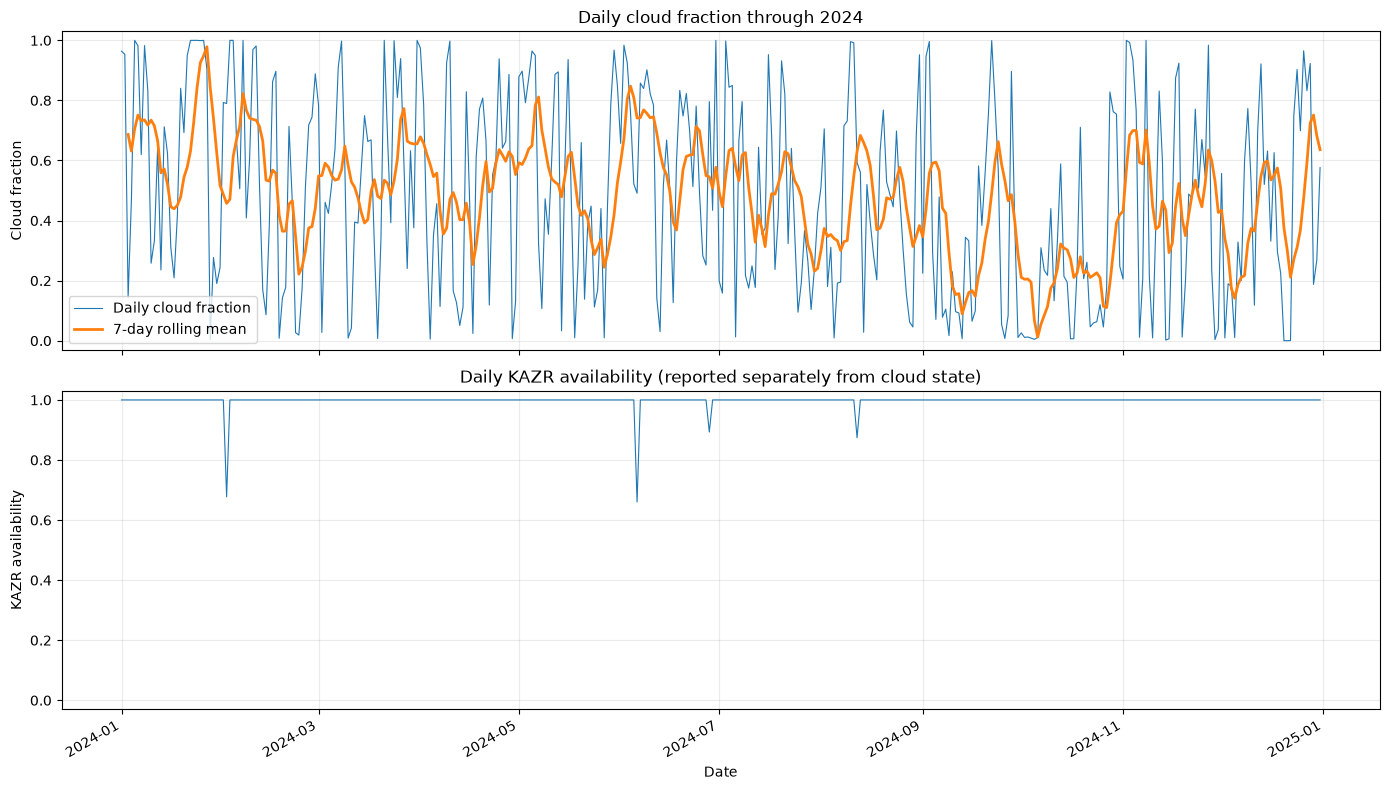

In [5]:
state_series = cloud_state_df["cloud_state"]
known = state_series.isin([0, 1])
cloudy = state_series.eq(1) # Identify timestamps with cloudy conditions
clear = state_series.eq(0) # Identify timestamps with clear conditions

known_count_day = known.astype(np.int32).resample("D").sum() # Count of known cloud-state timestamps per day
cloudy_count_day = cloudy.astype(np.int32).resample("D").sum() # Count of cloudy timestamps per day
clear_count_day = clear.astype(np.int32).resample("D").sum() # Count of clear timestamps per day
unknown_count_day = (~known).astype(np.int32).resample("D").sum() # Count of unknown cloud-state timestamps per day
raw_count_day = state_series.resample("D").size() # Total number of timestamps per day

daily_summary = pd.DataFrame({
    "n_timestamps": raw_count_day,
    "known_timestamps": known_count_day,
    "cloudy_timestamps": cloudy_count_day,
    "clear_timestamps": clear_count_day,
    "unknown_timestamps": unknown_count_day,
    "cloud_fraction": (cloudy_count_day / known_count_day.replace(0, np.nan)),
    "unknown_fraction": unknown_count_day / raw_count_day,
    "mean_layers_when_cloudy": (
        cloud_state_df["n_cloud_layers"].where(cloudy).resample("D").mean()
    ),
    "kazr_available_fraction": cloud_state_df["kazr_available"].astype(float).resample("D").mean(),
})

monthly_known = known.astype(np.int32).resample("MS").sum() # Same for monthly aggregation
monthly_cloudy = cloudy.astype(np.int32).resample("MS").sum() # Count of cloudy timestamps per month
monthly_unknown = (~known).astype(np.int32).resample("MS").sum() # Count of unknown cloud-state timestamps per month
monthly_total = state_series.resample("MS").size() # Total number of timestamps per month
monthly_summary = pd.DataFrame({
    "n_timestamps": monthly_total,
    "known_timestamps": monthly_known,
    "cloudy_timestamps": monthly_cloudy,
    "clear_timestamps": known.astype(np.int32).resample("MS").sum() - monthly_cloudy,
    "unknown_timestamps": monthly_unknown,
    "cloud_fraction": monthly_cloudy / monthly_known.replace(0, np.nan),
    "unknown_fraction": monthly_unknown / monthly_total,
    "kazr_available_fraction": cloud_state_df["kazr_available"].astype(float).resample("MS").mean(),
})

print("Daily summary, first and last five days:")
display(pd.concat([daily_summary.head(), daily_summary.tail()]))
print("Monthly summary:")
display(monthly_summary.round(4))

# Plot daily cloud fraction and KAZR availability
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(daily_summary.index, daily_summary["cloud_fraction"], linewidth=0.8, label="Daily cloud fraction")
axes[0].plot(
    daily_summary.index,
    daily_summary["cloud_fraction"].rolling(7, min_periods=3).mean(),
    linewidth=2,
    label="7-day rolling mean",
)
axes[0].set_ylabel("Cloud fraction")
axes[0].set_ylim(-0.03, 1.03)
axes[0].set_title("Daily cloud fraction through 2024")
axes[0].grid(True, alpha=0.25)
axes[0].legend()

axes[1].plot(daily_summary.index, daily_summary["kazr_available_fraction"], linewidth=0.8)
axes[1].set_ylabel("KAZR availability")
axes[1].set_ylim(-0.03, 1.03)
axes[1].set_title("Daily KAZR availability (reported separately from cloud state)")
axes[1].grid(True, alpha=0.25)
axes[1].set_xlabel("Date")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Cloud-state observations during KAZR unavailability

The cloud-layer product uses combined radar and micropulse-lidar observations, so we should not automatically relabel known cloud-layer states as unknown whenever KAZR is unavailable. 

This table will check how often the cloud-state product reports a known state during KAZR-available and KAZR-unavailable timestamps. 

In [6]:
availability_rows = []
for available_value, group in cloud_state_df.groupby("kazr_available", sort=False):
    group_known = group["cloud_state"].isin([0, 1])
    n_known = int(group_known.sum())
    availability_rows.append({
        "KAZR status": "Available" if available_value else "Unavailable",
        "n_timestamps": len(group),
        "fraction_of_year": len(group) / len(cloud_state_df),
        "known_state_fraction": float(group_known.mean()),
        "cloud_fraction_among_known": (
            float((group["cloud_state"] == 1).sum() / n_known) if n_known else np.nan
        ),
    })
availability_summary = pd.DataFrame(availability_rows).set_index("KAZR status")
display(availability_summary.round(4))

,n_timestamps,fraction_of_year,known_state_fraction,cloud_fraction_among_known
KAZR status,,,,
Available,7886269,0.9976,1.000,0.484
Unavailable,19331,0.0024,0.303,0.960


### 6. Segment the series into clear and cloudy runs

Recall a **run** is a consecutive sequence of observations with the same known state. A state change, an unknown state, or a timestep different from four seconds breaks a run. 

Also recall two duration convections are retained: 
- **Sample-supported duration:** number of timestamps × 4 seconds. This treats each 4-second observation as representing its following sampling interval and is the convention used for duration bands below.
- **First-to-last timestamp span:** last timestamp minus first timestamp. For a run containing two observations four seconds apart, this span is four seconds, while its sample-supported duration is eight seconds.

We will make a run **left- or right-censored** if it touches the beginning/end of the analysis window or is ajdacent to an unknown state or time gap. Its observed duration is then only a lower bound on the complete event duration. 

In [7]:
state = cloud_state_df["cloud_state"]
state_values = state.to_numpy(dtype=np.int8)
time_index = cloud_state_df.index
delta_values = time_index.to_series().diff().dt.total_seconds().to_numpy()
n_observations = len(state_values)

# Start a new segment when the state changes, a gap occurs, or either
# side of the boundary is unknown. Each unknown observation forms a break.
new_run = np.ones(n_observations, dtype=bool)
if n_observations > 1:
    new_run[1:] = ( #Same definition as before 
        (state_values[1:] != state_values[:-1])
        | (delta_values[1:] != EXPECTED_STEP_SECONDS)
        | (state_values[1:] == -1)
        | (state_values[:-1] == -1)
    )
all_run_starts = np.flatnonzero(new_run)
all_run_ends = np.r_[all_run_starts[1:] - 1, n_observations - 1]

# Keep only clear/cloudy runs; unknown states remain boundaries but are not events.
run_is_known = np.isin(state_values[all_run_starts], [0, 1])
run_starts = all_run_starts[run_is_known]
run_ends = all_run_ends[run_is_known]
run_states = state_values[run_starts]

start_times = time_index.to_numpy()[run_starts]
end_times = time_index.to_numpy()[run_ends]
n_timestamps = run_ends - run_starts + 1

event_summary = pd.DataFrame({
    "cloud_state": run_states,
    "start_time": start_times,
    "end_time": end_times,
    "n_timestamps": n_timestamps,
})
event_summary["state_label"] = event_summary["cloud_state"].map({0: "Clear", 1: "Cloudy"})
event_summary["sample_duration_seconds"] = event_summary["n_timestamps"] * EXPECTED_STEP_SECONDS
event_summary["sample_duration_minutes"] = event_summary["sample_duration_seconds"] / 60
event_summary["timestamp_span_seconds"] = (
    pd.to_datetime(event_summary["end_time"]) - pd.to_datetime(event_summary["start_time"])
).dt.total_seconds()

# An event is censored if its true start/end may extend beyond observed, continuous data.
left_censored = run_starts == 0
left_other = ~left_censored
left_censored[left_other] = (
    (state_values[run_starts[left_other] - 1] == -1)
    | (delta_values[run_starts[left_other]] != EXPECTED_STEP_SECONDS)
)

right_censored = run_ends == n_observations - 1
right_other = ~right_censored
next_positions = run_ends[right_other] + 1
right_censored[right_other] = (
    (state_values[next_positions] == -1)
    | (delta_values[next_positions] != EXPECTED_STEP_SECONDS)
)

event_summary["left_censored"] = left_censored
event_summary["right_censored"] = right_censored
event_summary["boundary_censored"] = left_censored | right_censored
complete_events = event_summary.loc[~event_summary["boundary_censored"]].copy()

display_names = {0: "Clear", 1: "Cloudy"}
print("Known-state runs:", f"{len(event_summary):,}")
print("Clear runs:", int((event_summary["cloud_state"] == 0).sum()))
print("Cloudy runs:", int((event_summary["cloud_state"] == 1).sum()))
print("Left-censored runs:", int(event_summary["left_censored"].sum()))
print("Right-censored runs:", int(event_summary["right_censored"].sum()))
print("Boundary-censored runs (left or right):", int(event_summary["boundary_censored"].sum()))
print("Unknown timestamps that break runs:", int((state == -1).sum()))
display(event_summary.head())

Known-state runs: 22,148
Clear runs: 11071
Cloudy runs: 11077
Left-censored runs: 12
Right-censored runs: 12
Boundary-censored runs (left or right): 17
Unknown timestamps that break runs: 13474


,cloud_state,start_time,end_time,n_timestamps,state_label,sample_duration_seconds,sample_duration_minutes,timestamp_span_seconds,left_censored,right_censored,boundary_censored
0,0,2024-01-01 00:00:00,2024-01-01 00:00:04,2,Clear,8,0.133333,4.0,True,False,True
1,1,2024-01-01 00:00:08,2024-01-01 19:30:04,17550,Cloudy,70200,1170.000000,70196.0,False,False,False
2,0,2024-01-01 19:30:08,2024-01-01 19:31:08,16,Clear,64,1.066667,60.0,False,False,False
3,1,2024-01-01 19:31:12,2024-01-01 19:31:32,6,Cloudy,24,0.400000,20.0,False,False,False
4,0,2024-01-01 19:31:36,2024-01-01 19:39:32,120,Clear,480,8.000000,476.0,False,False,False


## 7. Summarize run durations, including and excluding censored events

Here, we will construct an all-runs summary, describing the observed runs. However, events at a gap or analysis-window boundary can be only partly observed. We will compare with the complete-run summary. 

In [8]:
def summarize_durations(events: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for label, group in events.groupby("state_label"):
        values = group["sample_duration_minutes"]
        rows.append({
            "state": label,
            "n_runs": int(len(group)),
            "mean_minutes": float(values.mean()),
            "median_minutes": float(values.median()),
            "p25_minutes": float(values.quantile(0.25)),
            "p75_minutes": float(values.quantile(0.75)),
            "p90_minutes": float(values.quantile(0.90)),
            "maximum_minutes": float(values.max()),
            "left_censored_runs": int(group["left_censored"].sum()),
            "right_censored_runs": int(group["right_censored"].sum()),
        })
    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).set_index("state")

print("All observed known-state runs:")
display(summarize_durations(event_summary).round(2))
print("Complete runs only (excluding runs adjacent to an edge, gap, or unknown state):")
display(summarize_durations(complete_events).round(2))

All observed known-state runs:


,n_runs,mean_minutes,median_minutes,p25_minutes,p75_minutes,p90_minutes,maximum_minutes,left_censored_runs,right_censored_runs
state,,,,,,,,,
Clear,11071,24.50,2.53,0.67,13.13,55.0,3594.33,3,3
Cloudy,11077,23.01,1.53,0.73,6.00,27.0,2564.47,9,9


Complete runs only (excluding runs adjacent to an edge, gap, or unknown state):


,n_runs,mean_minutes,median_minutes,p25_minutes,p75_minutes,p90_minutes,maximum_minutes,left_censored_runs,right_censored_runs
state,,,,,,,,,
Clear,11065,24.46,2.53,0.67,13.13,55.0,3594.33,0,0
Cloudy,11066,22.85,1.53,0.73,6.00,26.6,2564.47,0,0


## 8. How often are runs short? 

Here, the thresholds below are descriptive checkpoints, not decisions about what counds as a real cloud event. We report both all observed runs and complete runs. 

,sample,state,threshold,n_runs_at_or_below,n_runs,percent_runs_at_or_below
0,All observed runs,Clear,≤ 30 seconds,2173,11071,19.63
1,All observed runs,Clear,≤ 1 minute,3711,11071,33.52
2,All observed runs,Clear,≤ 5 minutes,6837,11071,61.76
3,All observed runs,Clear,≤ 15 minutes,8496,11071,76.74
4,All observed runs,Cloudy,≤ 30 seconds,1922,11077,17.35
5,All observed runs,Cloudy,≤ 1 minute,4520,11077,40.81
6,All observed runs,Cloudy,≤ 5 minutes,8015,11077,72.36
7,All observed runs,Cloudy,≤ 15 minutes,9489,11077,85.66
8,Complete runs only,Clear,≤ 30 seconds,2171,11065,19.62
9,Complete runs only,Clear,≤ 1 minute,3709,11065,33.52


Percent of all observed runs in each duration band:


duration_band,≤30 sec,30–60 sec,1–5 min,5–15 min,>15 min
state_label,,,,,
Clear,19.6,13.9,28.2,15.0,23.3
Cloudy,17.4,23.5,31.6,13.3,14.3


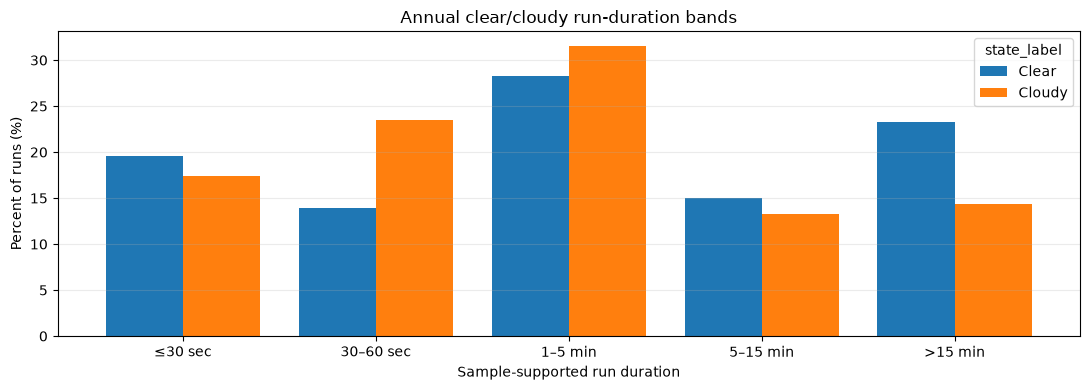

In [9]:
DURATION_THRESHOLDS_SECONDS = [30, 60, 300, 900]
threshold_labels = {30: "≤ 30 seconds", 60: "≤ 1 minute", 300: "≤ 5 minutes", 900: "≤ 15 minutes"}
short_run_rows = []

#Here, we summarize the number and percentage of runs that fall below specific duration thresholds for both all observed runs and complete runs only.
for sample_name, events in [("All observed runs", event_summary), ("Complete runs only", complete_events)]:
    for label, group in events.groupby("state_label"):
        durations = group["sample_duration_seconds"]
        for threshold in DURATION_THRESHOLDS_SECONDS:
            short_run_rows.append({
                "sample": sample_name,
                "state": label,
                "threshold": threshold_labels[threshold],
                "threshold_seconds": threshold,
                "n_runs_at_or_below": int((durations <= threshold).sum()),
                "n_runs": int(len(group)),
                "percent_runs_at_or_below": float(100 * (durations <= threshold).mean()) if len(group) else np.nan,
            })

short_run_summary = pd.DataFrame(short_run_rows)
display(short_run_summary.drop(columns="threshold_seconds").round(2))

DURATION_BINS = [0, 30, 60, 300, 900, np.inf]
DURATION_LABELS = ["≤30 sec", "30–60 sec", "1–5 min", "5–15 min", ">15 min"]
event_summary["duration_band"] = pd.cut(
    event_summary["sample_duration_seconds"],
    bins=DURATION_BINS,
    labels=DURATION_LABELS,
    right=True,
    include_lowest=True,
)
complete_events["duration_band"] = pd.cut(
    complete_events["sample_duration_seconds"],
    bins=DURATION_BINS,
    labels=DURATION_LABELS,
    right=True,
    include_lowest=True,
)

band_table = (
    pd.crosstab(event_summary["state_label"], event_summary["duration_band"], normalize="index") * 100
).reindex(columns=DURATION_LABELS, fill_value=0)
print("Percent of all observed runs in each duration band:")
display(band_table.round(1))

ax = band_table.T.plot(kind="bar", figsize=(11, 4), width=0.8)
ax.set_xlabel("Sample-supported run duration")
ax.set_ylabel("Percent of runs (%)")
ax.set_title("Annual clear/cloudy run-duration bands")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Plot the full duration distributions

Here, we will use the ECDF again to show the fraction of runs whose duration is at or below a given value. We will show complete runs separately so boundry-truncated events do not dominate the tail. 

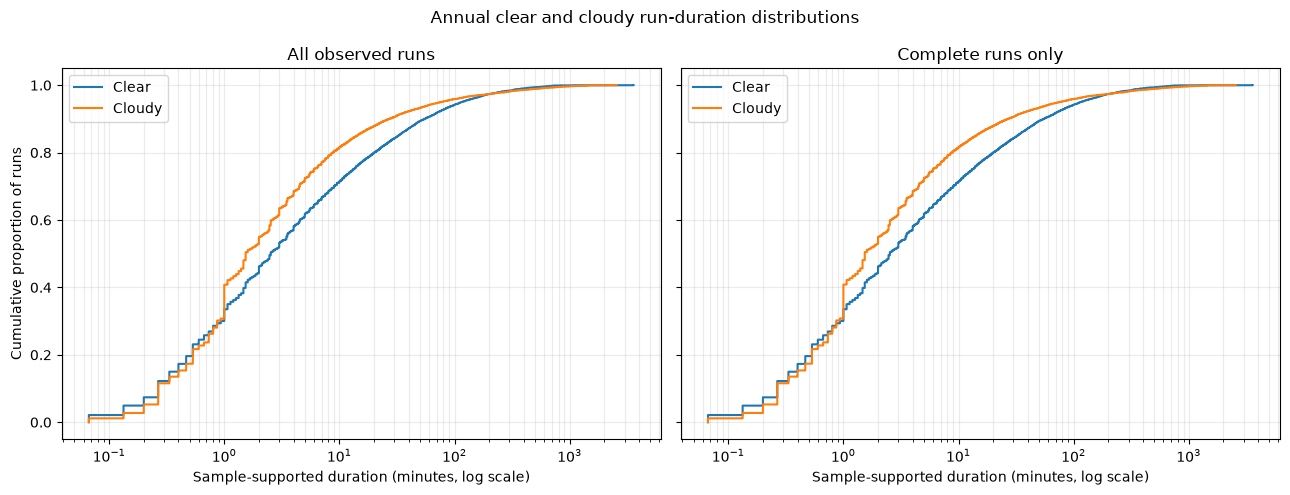

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, frame, title in [
    (axes[0], event_summary, "All observed runs"),
    (axes[1], complete_events, "Complete runs only"),
]:
    for label, group in frame.groupby("state_label"):
        values = np.sort(group["sample_duration_minutes"].to_numpy())
        if len(values) == 0:
            continue
        ecdf = np.arange(1, len(values) + 1) / len(values)
        ax.step(values, ecdf, where="post", label=label)
    ax.set_xscale("log")
    ax.set_xlabel("Sample-supported duration (minutes, log scale)")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Cumulative proportion of runs")
fig.suptitle("Annual clear and cloudy run-duration distributions")
plt.tight_layout()
plt.show()

## 10. Compare candidate temporal aggregation intervals

Now, for each bin, calculate: 

- **Cloud fraction:** cloudy known-state timestamps divided by known clear/cloudy timestamps.
- **Known-state coverage:** known cloud-state timestamps divided by timestamps actually present in the bin.
- **Timestamp coverage:** timestamps actually present divided by the number expected for a complete bin.
- **Bin composition:** fully clear, fully cloudy, mixed clear/cloudy, unknown-state observations, incomplete timestamp coverage, or no observed timestamps.

A strict rule: For an explicit aggregation-state diagnostic, a bin is labelled clear or cloudy only if every expected timestamp is present, every state is known, and the cloud fraction is not exactly 0.5. Otherwise, its aggregate state is unknown (`-1`). This avoids treating a partly observed bin or a tie as a confident state. 


In [11]:
state_series = cloud_state_df["cloud_state"]
known_numeric = state_series.isin([0, 1]).astype(np.int8)
cloudy_numeric = state_series.eq(1).astype(np.int8)
observed_one = pd.Series(1, index=cloud_state_df.index, dtype=np.int8) # Indicator for observed timestamps

aggregated = {} # Dictionary to store aggregated data frames for each interval
aggregation_rows = [] # List to store summary statistics for each aggregation interval
composition_order = [
    "Fully clear", "Fully cloudy", "Mixed clear/cloudy",
    "Unknown-state observations", "Incomplete timestamp coverage", "No observed timestamps"
]
composition_rows = [] # List to store composition information for each interval
analysis_elapsed_days = ( # Total elapsed time of the analysis period in days
    cloud_state_df.index[-1] - cloud_state_df.index[0]
    + pd.Timedelta(seconds=EXPECTED_STEP_SECONDS)
).total_seconds() / 86400

for interval in CANDIDATE_INTERVALS:
    interval_seconds = pd.Timedelta(interval).total_seconds()
    expected_per_bin = int(round(interval_seconds / EXPECTED_STEP_SECONDS))

    # Use bins anchored to midnight so day boundaries align consistently.
    known_count = known_numeric.resample(interval, origin="start_day", label="left", closed="left").sum()
    cloudy_count = cloudy_numeric.resample(interval, origin="start_day", label="left", closed="left").sum()
    observed_count = observed_one.resample(interval, origin="start_day", label="left", closed="left").sum()

    # Resample the known, cloudy, and observed indicators to the current aggregation interval.
    cloud_fraction = (cloudy_count / known_count.replace(0, np.nan)).rename("cloud_fraction")
    known_state_coverage = (known_count / observed_count.replace(0, np.nan)).rename("known_state_coverage")
    timestamp_coverage = (observed_count / expected_per_bin).clip(upper=1).rename("timestamp_coverage")

    # Determine which time bins are complete, which have all states known, and which are fully classifiable.
    complete_time_bin = observed_count.eq(expected_per_bin)
    all_states_known = known_count.eq(observed_count) & observed_count.gt(0)
    fully_classifiable = complete_time_bin & all_states_known

    # Assign aggregated state based on cloud fraction for fully classifiable bins.
    aggregated_state = pd.Series(-1, index=cloud_fraction.index, dtype=np.int8, name="aggregated_state")
    aggregated_state.loc[fully_classifiable & cloud_fraction.gt(0.5)] = 1
    aggregated_state.loc[fully_classifiable & cloud_fraction.lt(0.5)] = 0
    # Exact 50/50 ties remain unknown. Aggregated state is -1 for unknown, 0 for clear, and 1 for cloudy.

    # Determine the composition of each time bin based on observed timestamps, known states, and cloud fraction.
    composition = pd.Series("Unknown-state observations", index=cloud_fraction.index, dtype="object")
    composition.loc[observed_count.eq(0)] = "No observed timestamps"
    composition.loc[observed_count.gt(0) & observed_count.lt(expected_per_bin)] = "Incomplete timestamp coverage"
    complete_time = observed_count.eq(expected_per_bin)
    composition.loc[complete_time & known_count.lt(observed_count)] = "Unknown-state observations"
    composition.loc[complete_time & all_states_known & cloud_fraction.eq(0)] = "Fully clear"
    composition.loc[complete_time & all_states_known & cloud_fraction.eq(1)] = "Fully cloudy"
    composition.loc[complete_time & all_states_known & cloud_fraction.gt(0) & cloud_fraction.lt(1)] = "Mixed clear/cloudy"

    frame = pd.DataFrame({# Data frame summarizing the aggregated state and composition for the current interval
        "cloud_fraction": cloud_fraction,
        "known_state_coverage": known_state_coverage,
        "timestamp_coverage": timestamp_coverage,
        "n_observed_timestamps": observed_count,
        "aggregated_state": aggregated_state,
        "bin_composition": composition,
    })
    aggregated[interval] = frame

    previous_bin_state = aggregated_state.shift() # Shift the aggregated state to align previous bin with current bin for transition analysis
    bin_deltas = aggregated_state.index.to_series().diff().dt.total_seconds() # Time difference between consecutive bins in seconds
    valid_transition_pair = ( # Identify valid adjacent bin pairs for transition analysis
        aggregated_state.isin([0, 1])
        & previous_bin_state.isin([0, 1])
        & bin_deltas.eq(interval_seconds)
    )
    n_valid_pairs = int(valid_transition_pair.sum())
    n_changes = int(
        (aggregated_state[valid_transition_pair].to_numpy()
         != previous_bin_state[valid_transition_pair].to_numpy()).sum()
    )

    distribution = cloud_fraction.dropna()
    aggregation_rows.append({
        "interval": interval,
        "n_bins": len(frame),
        "median_cloud_fraction": float(distribution.median()) if len(distribution) else np.nan,
        "p10_cloud_fraction": float(distribution.quantile(0.10)) if len(distribution) else np.nan,
        "p90_cloud_fraction": float(distribution.quantile(0.90)) if len(distribution) else np.nan,
        "mean_known_state_coverage": float(known_state_coverage.mean()),
        "mean_timestamp_coverage": float(timestamp_coverage.mean()),
        "fully_classified_bins": int(fully_classifiable.sum()),
        "tie_or_other_unknown_aggregate_bins": int((aggregated_state == -1).sum()),
        "valid_adjacent_bin_pairs": n_valid_pairs,
        "state_changes_between_bins": n_changes,
        "changes_per_100_days": 100 * n_changes / analysis_elapsed_days if analysis_elapsed_days else np.nan,
        "change_fraction_of_valid_pairs": n_changes / n_valid_pairs if n_valid_pairs else np.nan,
    })

    comp_pct = (composition.value_counts(normalize=True) * 100).reindex(composition_order, fill_value=0)
    comp_pct.name = interval
    composition_rows.append(comp_pct)

aggregation_summary = pd.DataFrame(aggregation_rows).set_index("interval")
composition_summary = pd.DataFrame(composition_rows).reindex(columns=composition_order, fill_value=0)
composition_summary.index.name = "interval"

print("Aggregation summary:")
display(aggregation_summary.round(4))
print("Percentage of bins in each composition category:")
display(composition_summary.round(2))

Aggregation summary:


,n_bins,median_cloud_fraction,p10_cloud_fraction,p90_cloud_fraction,mean_known_state_coverage,mean_timestamp_coverage,fully_classified_bins,tie_or_other_unknown_aggregate_bins,valid_adjacent_bin_pairs,state_changes_between_bins,changes_per_100_days,change_fraction_of_valid_pairs
interval,,,,,,,,,,,,
20s,1581120,0.0000,0.0,1.0,0.9983,1.0,1578415,2705,1578403,19746,5395.0820,0.0125
1min,527040,0.0667,0.0,1.0,0.9983,1.0,526132,908,526120,14783,4039.0710,0.0281
5min,105408,0.3067,0.0,1.0,0.9983,1.0,105220,188,105211,5213,1424.3169,0.0495


Percentage of bins in each composition category:


,Fully clear,Fully cloudy,Mixed clear/cloudy,Unknown-state observations,Incomplete timestamp coverage,No observed timestamps
interval,,,,,,
20s,50.94,47.82,1.07,0.17,0.0,0.0
1min,49.78,46.64,3.40,0.17,0.0,0.0
5min,45.65,43.28,10.90,0.18,0.0,0.0


### Plot bin composition and cloud-fraction series

Note: A mixed bin contains both clear and cloudy samples, while a fully clear/cloudy bin is uniform across all known timestamps. Incomplete or unknown bins are shown separately. 

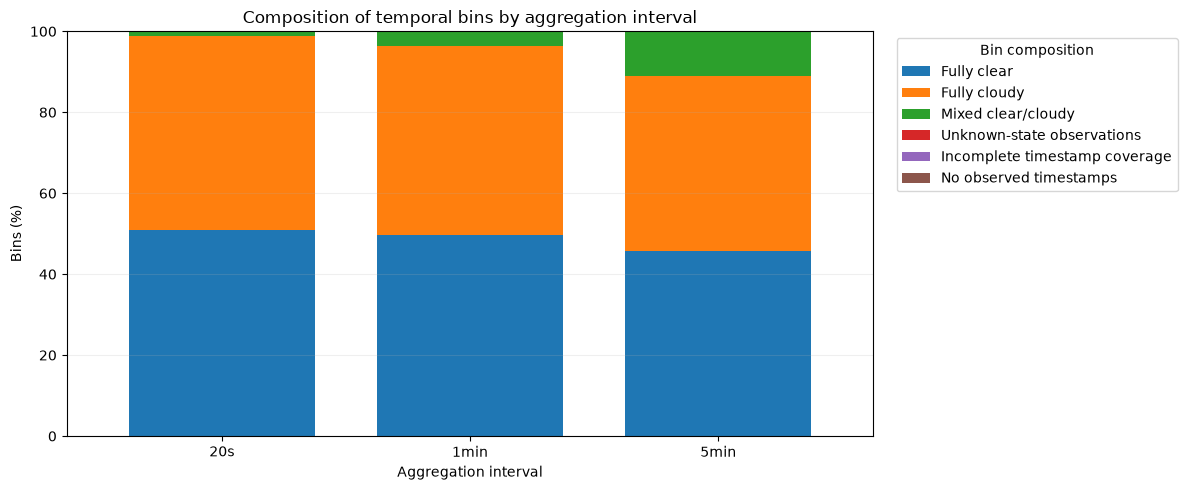

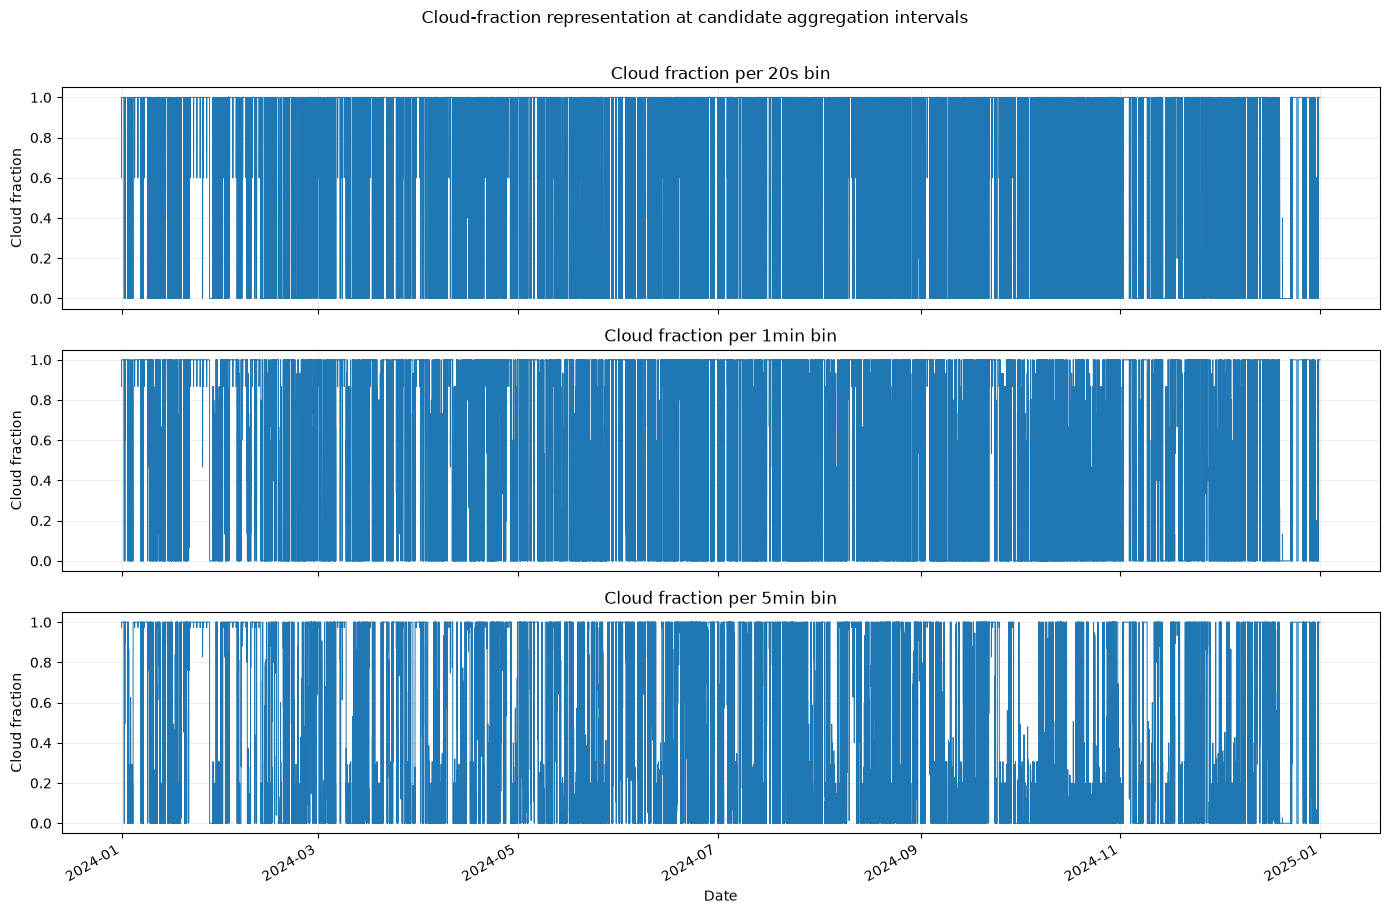

In [12]:
ax = composition_summary.plot(kind="bar", stacked=True, figsize=(12, 5), width=0.75)
ax.set_xlabel("Aggregation interval")
ax.set_ylabel("Bins (%)")
ax.set_title("Composition of temporal bins by aggregation interval")
ax.grid(axis="y", alpha=0.2)
ax.legend(title="Bin composition", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(CANDIDATE_INTERVALS), 1, figsize=(14, 9), sharex=True)
for ax, interval in zip(axes, CANDIDATE_INTERVALS):
    frame = aggregated[interval]
    ax.step(frame.index, frame["cloud_fraction"], where="post", linewidth=0.7)
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel("Cloud fraction")
    ax.set_title(f"Cloud fraction per {interval} bin")
    ax.grid(True, alpha=0.2)
axes[-1].set_xlabel("Date")
fig.suptitle("Cloud-fraction representation at candidate aggregation intervals", y=1.01)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 11. Compare transitions on the same elapsed-time basis

The fraction of adjacent bins that change state is **not directly comparable across aggregation intervals**, because a pair of five-minute bins spans more time than a pair of twenty-second bins. 

Therefore, we must report both the change fraction among valid adjacent pairs and the number of observed aggregate-state changes per 100 calender days. 

The per-100-day value has a consistent elapsed-time denominator, however, it is still a count of transitions in the aggregated representation: coarser intervals can suppress changes that occur within a bin. Thus, it is a diagnostic for comparing information loss. 

In [13]:
# Native four-second transition baseline, using only consecutive known-state pairs.
previous_native = state_series.shift()
native_delta = state_series.index.to_series().diff().dt.total_seconds()
native_pairs = ( # Identify valid consecutive known-state pairs for the native four-second interval
    state_series.isin([0, 1])
    & previous_native.isin([0, 1])
    & native_delta.eq(EXPECTED_STEP_SECONDS)
)
native_changes = int( # Count the number of state changes between consecutive valid native pairs
    (state_series[native_pairs].to_numpy() != previous_native[native_pairs].to_numpy()).sum()
)

transition_comparison = pd.DataFrame([{
    "interval": "4s native",
    "valid_adjacent_pairs": int(native_pairs.sum()),
    "state_changes": native_changes,
    "change_fraction_of_valid_pairs": native_changes / int(native_pairs.sum()) if native_pairs.sum() else np.nan,
    "changes_per_100_days": 100 * native_changes / analysis_elapsed_days if analysis_elapsed_days else np.nan,
}])
transition_comparison = pd.concat([
    transition_comparison,
    aggregation_summary.reset_index()[[
        "interval", "valid_adjacent_bin_pairs", "state_changes_between_bins",
        "change_fraction_of_valid_pairs", "changes_per_100_days"
    ]].rename(columns={
        "valid_adjacent_bin_pairs": "valid_adjacent_pairs",
        "state_changes_between_bins": "state_changes",
    })
], ignore_index=True)

display(transition_comparison.set_index("interval").round(4))

,valid_adjacent_pairs,state_changes,change_fraction_of_valid_pairs,changes_per_100_days
interval,,,,
4s native,7892114,22136,0.0028,6048.0874
20s,1578403,19746,0.0125,5395.0820
1min,526120,14783,0.0281,4039.0710
5min,105211,5213,0.0495,1424.3169


## 12. Interpretations

There is a lot to interpret in the results of this notebook. Firstly, KAZR availability is 95.7555% overall. However, the availability comparison reveals that when KAZR is unavailable, only 30.3% of timestamps have a known cloud state. Among those known states, 96.0% are cloudy (Section 5). 

This suggests that unknown states are strongly associated with instrument downtime, and the unavailable observations are not simply a random sample of the year. We should preserve that distinction in the modeling pipeline. 

Additionally, the annual cloud fraction, calculated over known cloud-state timestamps, is roughly 48.44%. Monthly summaries showed clear changes across the observed year. We see the daily plot is much more variable than the monthly summary, and the seven-day rolling mean highlights some broader periods of changing cloudiness. 

For our model, this matters because a single day may have very different state dynamics from the next. It supports using a temporally ordered train/test split and evaluating the model across a range of conditions, rahter than relying on a random split that may mix very similar neighboring observations between training and testing. 

Next, the annual run durations confirm that short events are common. Importantly, we should note the difference between the means and medians. A typical observed run is only a few minutes long, but a small number of exceptionally long runs pull the means upward. 

We can also note that the effect of boundary censoring is small in this dataset. Removing the 17 runs classified as censored barely changes the duration quantiles. 

Also an important distinction: a continuous cloudy state does not necessarily mean that the same cloud persisted for 42 hours. Our label means that the product continued to detect at least one hydrometeor layer at the site. Different clouds or cloud layers could contribute to that period. 

Next, we can see cloudy runs are somewhat more concentrated in the short-duration bands. Approximately 72.4% of cloudy runs last five minutes or less, compared with 61.8% of clear runs. Conversely, 23.3% of clear runs exceed 15 minutes, versus 14.3% of cloudy runs (Section 8)

This is pretty important for defining our target, but does not justify declaring every short run noise. We should probably preserve the original state series and avoid applying a filter until we have a justified reason. 

Finally, a really important conclusion: 20 seconds looks like the best temporal aggregation for a starting point (Section 10). We can see as the aggregation interval grows, bins containing both clear and cloudy observations become more common: 1.07% at 20 seconds, 3.40% at one minute, and 10.90% at five minutes. 

This is expected as longer intervals reduce the number of rows but smooth over more short-lived changes. The transition comparison makes this more concrete (Section 11). We can see a five minute aggregation suppresses roughly three-quarters of the observed native transitions. By contract, the 20 second aggregation preserves nearly nin out of every 10. 

That said, a one minute aggregation seems reasonable if reducing the dataset size becomes important. 



## 13. Conclusions and Next Steps

The annual temporal-dynamics analysis confirms that the 2024 cloud-state series is structurally complete, with 366 daily files. All timestamps are regularly spaced, and there are no missing data, duplicate timestamps or gaps greater than four seconds. Approximately 48.44% of timestamps with known states were classified as cloudy. Monthly cloud fractions varied substantially, demonstrating that cloud conditions differ considerably across the observed year. Unknown states were rare overall but strongly associated with KAZR unavailability, so they must remain destinct from clear-sky observations. 

As expected, run-duration distributions are strongly right-skewed. Median clear and cloudy runs lasted approximately 2.53 and 1.53 minutes, respectively, while a small number of events extended for many hours. The small difference between all-run and complete-run summaries indicates that boundary censoring does not materially affect the main duration findings. However, a continuous cloudy label represents persistent cloud detection at the site, not necessarily the persistence of one individual physical cloud. 

Temporal aggregation increasingly smooths the state series. Twenty second bins preserve approximately 89.2% of native observed transitions, compared with 66.8% at one minute and 23.5% at five minutes. Furthermore, mixed clear/cloudy bins increase from 1.07% at 20 seconds to 10.90% at five minutes. 

These results support using 20 second aggregation as the leading candidate and one minute aggregation as a sensitivity comparison, while retaining cloud fraction as a continuous summary for mixed bins. 

Next, we will construct and validate candidate modeling features and future persistence outcomes at these candidate resolutions. The prediction horizon and exact target definition will be selected based on the observed behavior. 

The final pipeline will apply QC in memory, preserve cloud-state uncertainty, and save the final eligible modeling dataset. 